# Task 6 (Part B): Feature Selection, Dimensionality Reduction & Tuning

In this notebook, we explore three ways to improve our RainTomorrow classifier on the 115 preprocessed features:
1. Feature importance ranking with Random Forest and subset comparison.
2. Comparing feature selection against PCA (90% variance) and LDA (1D).
3. Tuning HistGradientBoostingClassifier with RandomizedSearchCV (15 candidates x 5 folds = 75 fits) and checking final test performance.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, confusion_matrix

X_PATH = "data/X_scaled_cleaned.csv" if os.path.exists("data/X_scaled_cleaned.csv") else "X_scaled_cleaned.csv"
Y_PATH = "data/y_cleaned.csv" if os.path.exists("data/y_cleaned.csv") else "y_cleaned.csv"
RANDOM_STATE = 42

X = pd.read_csv(X_PATH)
y = pd.read_csv(Y_PATH).iloc[:, 0]

# same 70/30 split as Task 4 and Task 5
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Train shape:", X_train.shape, "Rain ratio:", round(y_train.mean(), 4))
print("Test shape:", X_test.shape, "Rain ratio:", round(y_test.mean(), 4))

Train shape: (99535, 115) Rain ratio: 0.2242
Test shape: (42658, 115) Rain ratio: 0.2242


### 1. Feature Importance Ranking (Random Forest)
Fit a Random Forest on the training set to rank all 115 features by importance.

RF fit time: 1.09s


,feature,importance,cum_importance
0,Humidity3pm,0.2378,0.2378
1,Rainfall,0.0949,0.3327
2,Sunshine,0.0688,0.4015
3,Pressure3pm,0.0587,0.4602
4,Humidity9am,0.0537,0.5139
5,WindGustSpeed,0.0534,0.5673
6,Cloud3pm,0.0522,0.6194
7,Pressure9am,0.0506,0.6700
8,RainToday,0.0415,0.7115
9,Temp3pm,0.0369,0.7485


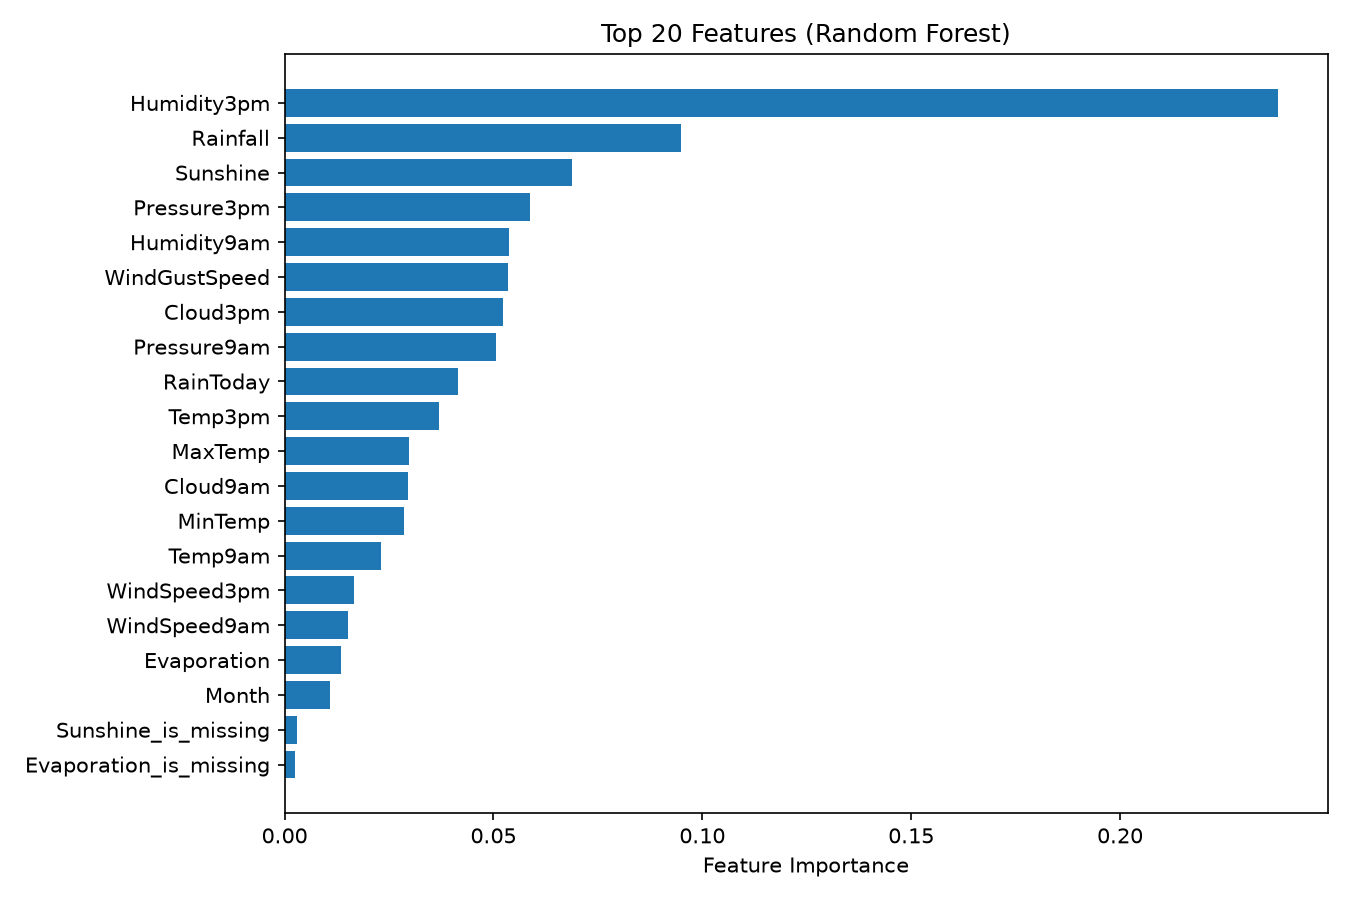

In [2]:
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)
print(f"RF fit time: {time.time() - t0:.2f}s")

imp = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False).reset_index(drop=True)
imp["cum_importance"] = imp["importance"].cumsum()

display(imp.head(15).round(4))

# plot top 20 features
top20 = imp.head(20).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top20["feature"], top20["importance"])
plt.xlabel("Feature Importance")
plt.title("Top 20 Features (Random Forest)")
plt.tight_layout()
plt.show()

### 2. Feature Subset Evaluation
Test different numbers of top features using 5-fold CV on the training set to check the trade-off between performance and speed.

k=10: AUC=0.8737, F1=0.6005, time=0.41s
k=20: AUC=0.8792, F1=0.6119, time=0.46s
k=30: AUC=0.8812, F1=0.6165, time=0.70s
k=40: AUC=0.8818, F1=0.6167, time=0.82s
k=60: AUC=0.8832, F1=0.6202, time=0.74s
k=80: AUC=0.8847, F1=0.6238, time=0.84s
k=115: AUC=0.8862, F1=0.6258, time=1.18s


,k,cv_auc,cv_f1,cv_acc,fit_time
0,10,0.8737,0.6005,0.8487,0.4083
1,20,0.8792,0.6119,0.8519,0.4627
2,30,0.8812,0.6165,0.8534,0.6971
3,40,0.8818,0.6167,0.8533,0.8181
4,60,0.8832,0.6202,0.8546,0.7427
5,80,0.8847,0.6238,0.8554,0.8412
6,115,0.8862,0.6258,0.8563,1.1806


Best k by CV AUC: 115


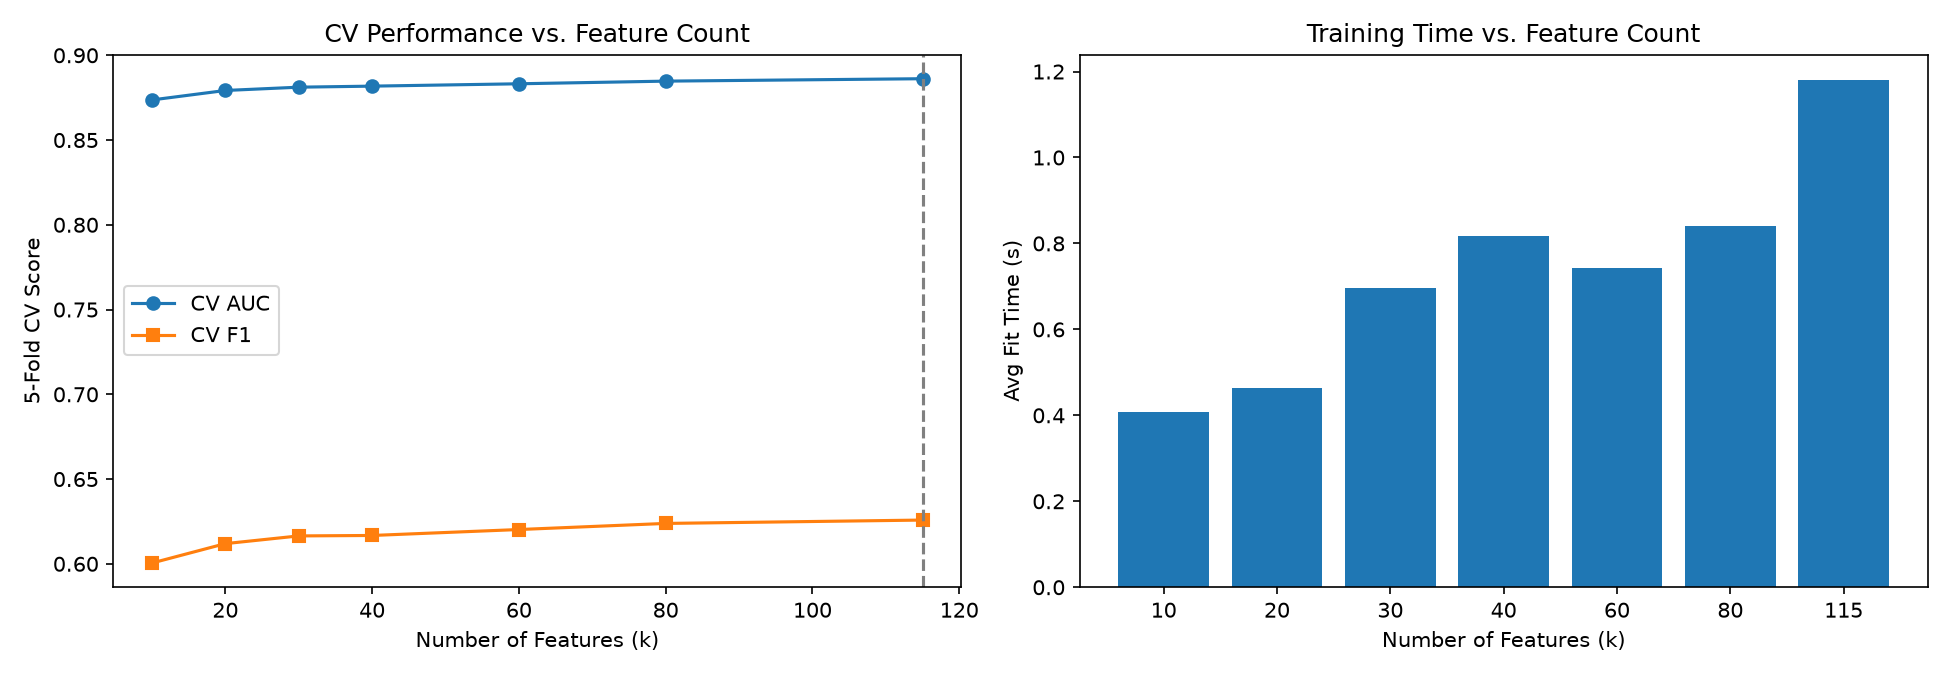

In [3]:
k_list = [10, 20, 30, 40, 60, 80, X_train.shape[1]]
rows = []

for k in k_list:
    cols = imp["feature"].iloc[:k].tolist()
    clf = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
    scores = cross_validate(
        clf, X_train[cols], y_train,
        cv=cv, scoring=["roc_auc", "f1", "accuracy"]
    )
    rows.append({
        "k": k,
        "cv_auc": scores["test_roc_auc"].mean(),
        "cv_f1": scores["test_f1"].mean(),
        "cv_acc": scores["test_accuracy"].mean(),
        "fit_time": scores["fit_time"].mean()
    })
    print(f"k={k}: AUC={rows[-1]['cv_auc']:.4f}, F1={rows[-1]['cv_f1']:.4f}, time={rows[-1]['fit_time']:.2f}s")

res_df = pd.DataFrame(rows)
display(res_df.round(4))

best_k = int(res_df.loc[res_df["cv_auc"].idxmax(), "k"])
compact_k = 40
print("Best k by CV AUC:", best_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(res_df["k"], res_df["cv_auc"], marker="o", label="CV AUC")
axes[0].plot(res_df["k"], res_df["cv_f1"], marker="s", label="CV F1")
axes[0].axvline(best_k, color="gray", linestyle="--")
axes[0].set_xlabel("Number of Features (k)")
axes[0].set_ylabel("5-Fold CV Score")
axes[0].set_title("CV Performance vs. Feature Count")
axes[0].legend()

axes[1].bar(res_df["k"].astype(str), res_df["fit_time"])
axes[1].set_xlabel("Number of Features (k)")
axes[1].set_ylabel("Avg Fit Time (s)")
axes[1].set_title("Training Time vs. Feature Count")

plt.tight_layout()
plt.show()

### 3. Feature Selection vs. PCA & LDA
Compare keeping the top 40 original features with PCA (90% variance) and regularized LDA (1D projection for binary classes). Pipelines are used inside CV to avoid data leakage.

PCA components for 90% variance: 35 (0.902)


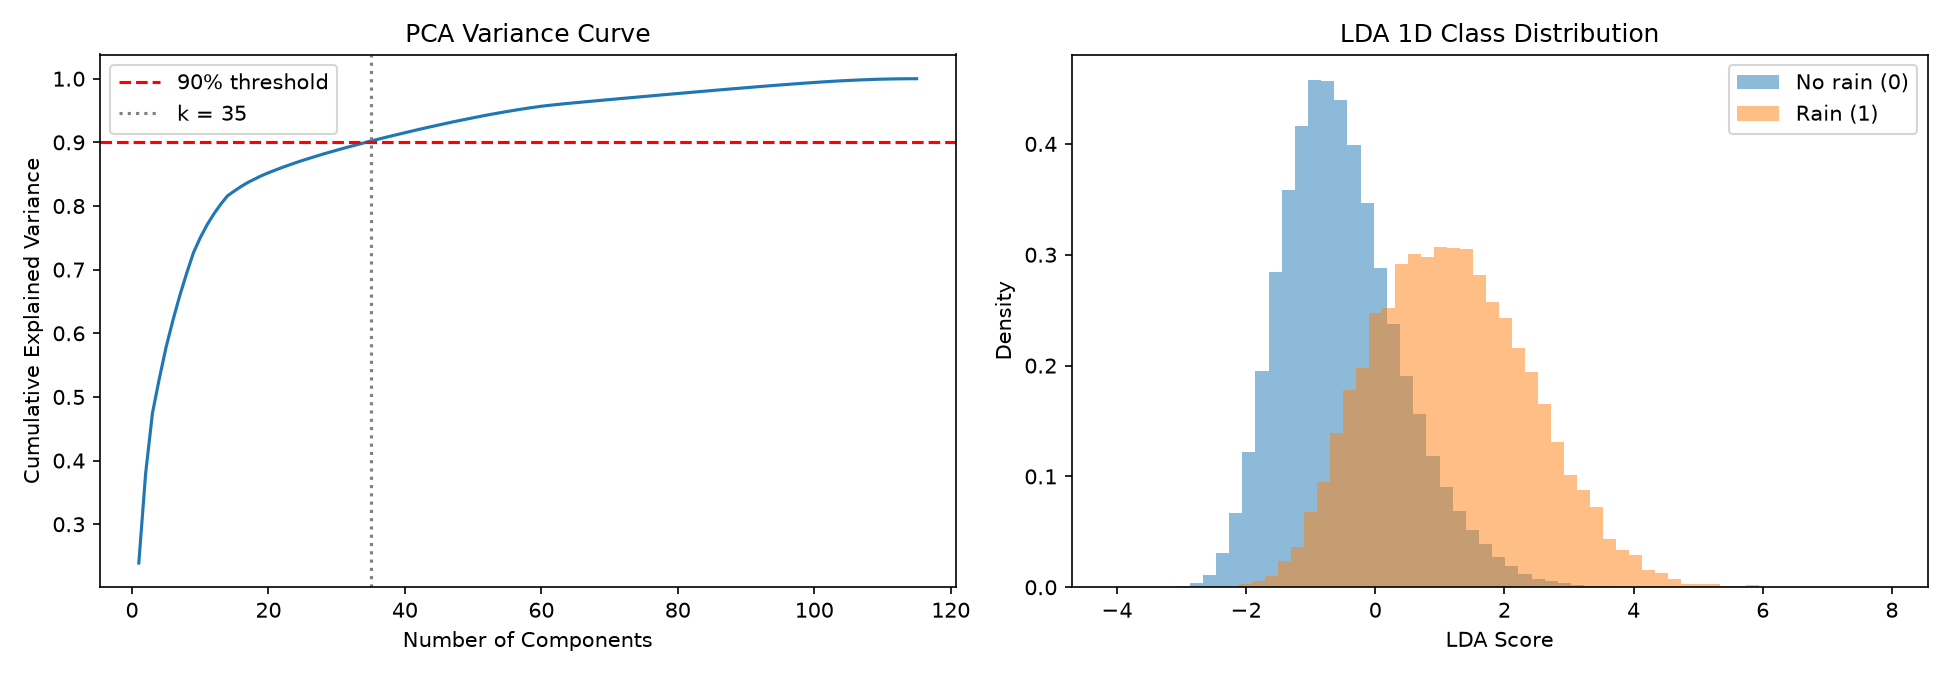

,Method,Dims,CV AUC,CV F1,CV Acc,Fit Time (s)
0,All 115 features,115,0.8862,0.6258,0.8563,1.1966
1,Top 40 selected,40,0.8818,0.6167,0.8533,0.5767
2,PCA 90% (k=35),35,0.8750,0.6066,0.8479,0.6385
3,LDA 1D (shrinkage),1,0.8663,0.5932,0.8457,0.9553


In [4]:
compact_cols = imp["feature"].iloc[:compact_k].tolist()

# check PCA variance curve on training data
pca = PCA(random_state=RANDOM_STATE).fit(X_train)
cum_var = np.cumsum(pca.explained_variance_ratio_)
k_pca = int(np.argmax(cum_var >= 0.90) + 1)
print(f"PCA components for 90% variance: {k_pca} ({cum_var[k_pca - 1]:.3f})")

# check 1D LDA projection (shrinkage avoids singular within-class scatter)
lda = LinearDiscriminantAnalysis(n_components=1, solver="eigen", shrinkage="auto")
z_lda = lda.fit_transform(X_train, y_train).ravel()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(range(1, len(cum_var) + 1), cum_var)
axes[0].axhline(0.90, color="r", linestyle="--", label="90% threshold")
axes[0].axvline(k_pca, color="gray", linestyle=":", label=f"k = {k_pca}")
axes[0].set_xlabel("Number of Components")
axes[0].set_ylabel("Cumulative Explained Variance")
axes[0].set_title("PCA Variance Curve")
axes[0].legend()

axes[1].hist(z_lda[y_train == 0], bins=50, density=True, alpha=0.5, label="No rain (0)")
axes[1].hist(z_lda[y_train == 1], bins=50, density=True, alpha=0.5, label="Rain (1)")
axes[1].set_xlabel("LDA Score")
axes[1].set_ylabel("Density")
axes[1].set_title("LDA 1D Class Distribution")
axes[1].legend()

plt.tight_layout()
plt.show()

# 5-fold CV comparison
dr_setups = [
    ("All 115 features", HistGradientBoostingClassifier(random_state=RANDOM_STATE), X_train, 115),
    (f"Top {compact_k} selected", HistGradientBoostingClassifier(random_state=RANDOM_STATE), X_train[compact_cols], compact_k),
    (f"PCA 90% (k={k_pca})", Pipeline([
        ("pca", PCA(n_components=0.90, random_state=RANDOM_STATE)),
        ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))
    ]), X_train, k_pca),
    ("LDA 1D (shrinkage)", Pipeline([
        ("lda", LinearDiscriminantAnalysis(n_components=1, solver="eigen", shrinkage="auto")),
        ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))
    ]), X_train, 1)
]

dr_rows = []
for name, est, X_in, dims in dr_setups:
    scores = cross_validate(est, X_in, y_train, cv=cv, scoring=["roc_auc", "f1", "accuracy"])
    dr_rows.append({
        "Method": name,
        "Dims": dims,
        "CV AUC": scores["test_roc_auc"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV Acc": scores["test_accuracy"].mean(),
        "Fit Time (s)": scores["fit_time"].mean()
    })

dr_df = pd.DataFrame(dr_rows)
display(dr_df.round(4))

### 4. Hyperparameter Tuning (HistGradientBoostingClassifier)
Tune learning rate, tree size, and L2 regularization on the best feature subset using 5-fold RandomizedSearchCV (15 candidates x 5 folds = 75 fits, scoring = ROC-AUC).

In [5]:
best_cols = imp["feature"].iloc[:best_k].tolist()

param_grid = {
    "learning_rate": [0.03, 0.05, 0.08, 0.1, 0.15],
    "max_iter": [200, 300, 400],
    "max_leaf_nodes": [31, 63, 127],
    "max_depth": [None, 8, 12, 16],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 0.1, 1.0, 5.0]
}

base_hgb = HistGradientBoostingClassifier(
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=RANDOM_STATE
)

t0 = time.time()
search = RandomizedSearchCV(
    base_hgb,
    param_distributions=param_grid,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=RANDOM_STATE,
    verbose=2
)
search.fit(X_train[best_cols], y_train)

print(f"Search done in {time.time() - t0:.1f}s")
print("Best CV AUC:", round(search.best_score_, 4))
print("Best params:", search.best_params_)

# show top 5 parameter sets
cv_res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cols_show = [
    "rank_test_score", "mean_test_score", "param_learning_rate",
    "param_max_leaf_nodes", "param_max_depth", "param_min_samples_leaf", "param_l2_regularization"
]
display(cv_res[cols_show].head(5).round(4))

Fitting 5 folds for each of 15 candidates, totalling 75 fits
[CV] END l2_regularization=0.1, learning_rate=0.08, max_depth=16, max_iter=400, max_leaf_nodes=63, min_samples_leaf=100; total time=   3.5s
[CV] END l2_regularization=0.1, learning_rate=0.08, max_depth=16, max_iter=400, max_leaf_nodes=63, min_samples_leaf=100; total time=   3.0s
[CV] END l2_regularization=0.1, learning_rate=0.08, max_depth=16, max_iter=400, max_leaf_nodes=63, min_samples_leaf=100; total time=   2.5s
[CV] END l2_regularization=0.1, learning_rate=0.08, max_depth=16, max_iter=400, max_leaf_nodes=63, min_samples_leaf=100; total time=   2.7s
[CV] END l2_regularization=0.1, learning_rate=0.08, max_depth=16, max_iter=400, max_leaf_nodes=63, min_samples_leaf=100; total time=   3.2s
[CV] END l2_regularization=1.0, learning_rate=0.05, max_depth=16, max_iter=400, max_leaf_nodes=127, min_samples_leaf=50; total time=   7.2s
[CV] END l2_regularization=1.0, learning_rate=0.05, max_depth=16, max_iter=400, max_leaf_nodes=127,

,rank_test_score,mean_test_score,param_learning_rate,param_max_leaf_nodes,param_max_depth,param_min_samples_leaf,param_l2_regularization
0,1,0.8938,0.05,127,16,50,1.0
1,2,0.8928,0.08,63,16,100,0.1
2,3,0.8924,0.05,63,8,100,1.0
3,4,0.8923,0.05,63,None,50,0.0
4,5,0.8922,0.03,127,None,20,1.0


### 5. Final Evaluation on Test Set
Evaluate the default full-feature model, PCA pipeline, compact Top-40 model, and the tuned model on the held-out 30% test set.

,Model,Dims,Train Acc,Test Acc,Precision,Recall,F1,Test AUC,Fit Time (s)
0,Default HistGB (115 feat),115,0.8654,0.8572,0.7542,0.5387,0.6285,0.8883,1.3670
1,PCA 90% (k=35) + HistGB,35,0.8621,0.8498,0.7280,0.5266,0.6111,0.8759,0.7774
2,Default HistGB (Top 40),40,0.8632,0.8556,0.7480,0.5365,0.6249,0.8840,0.7269
3,Tuned HistGB (k=115),115,0.9001,0.8615,0.7565,0.5637,0.6461,0.8973,6.1317


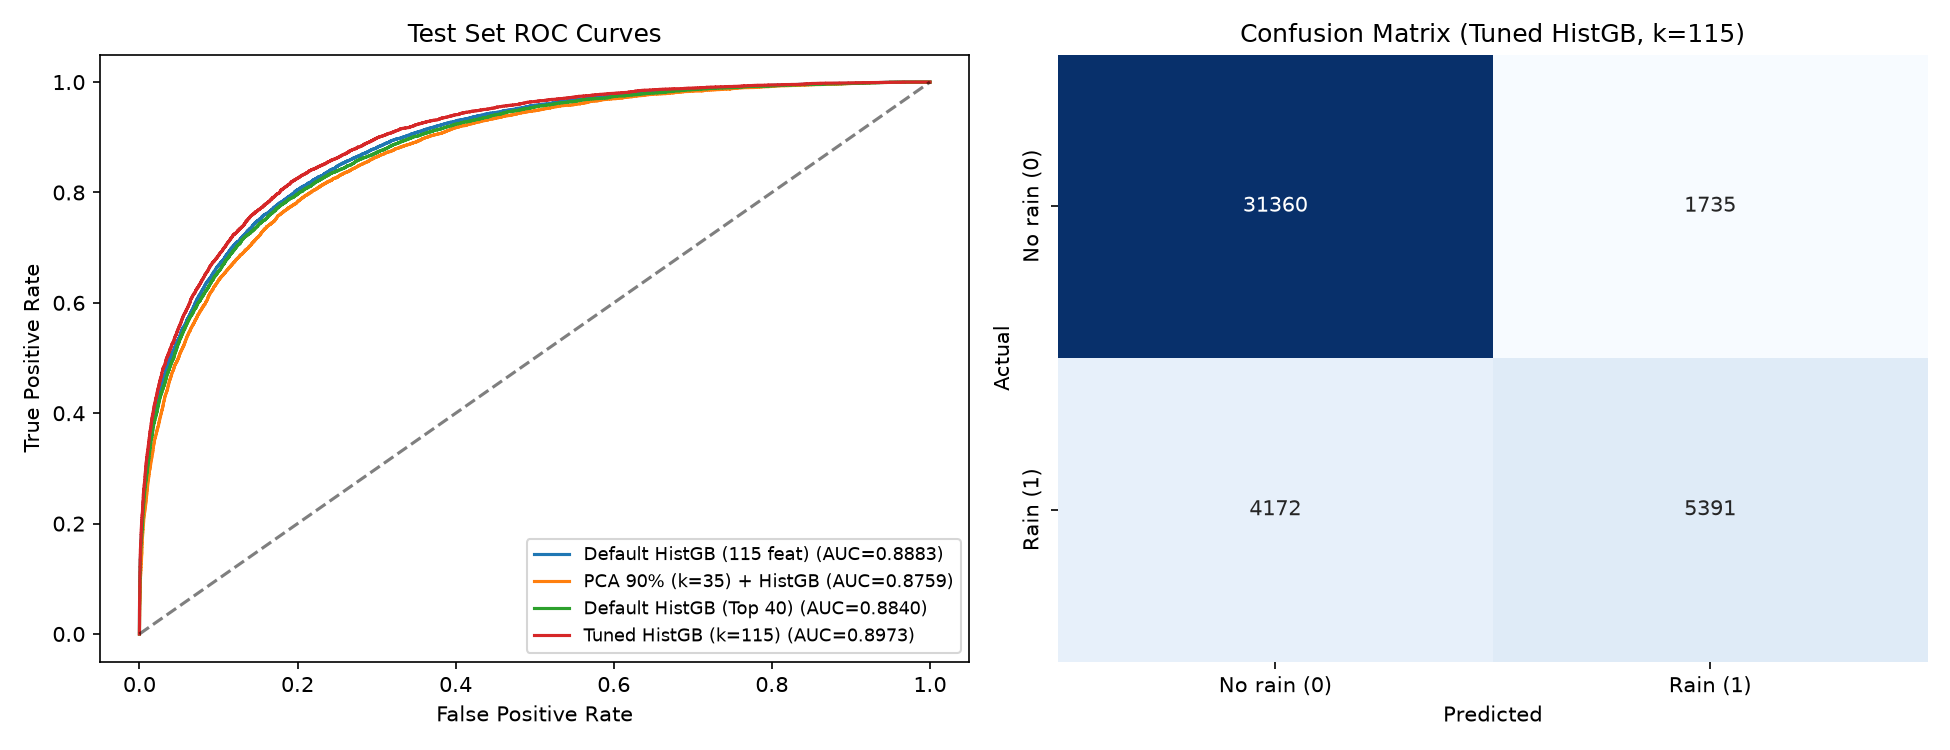

In [6]:
tuned_hgb = HistGradientBoostingClassifier(
    **search.best_params_,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=RANDOM_STATE
)

final_runs = [
    ("Default HistGB (115 feat)", HistGradientBoostingClassifier(random_state=RANDOM_STATE), X_train.columns.tolist(), 115),
    (f"PCA 90% (k={k_pca}) + HistGB", Pipeline([
        ("pca", PCA(n_components=0.90, random_state=RANDOM_STATE)),
        ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))
    ]), X_train.columns.tolist(), k_pca),
    (f"Default HistGB (Top {compact_k})", HistGradientBoostingClassifier(random_state=RANDOM_STATE), compact_cols, compact_k),
    (f"Tuned HistGB (k={best_k})", tuned_hgb, best_cols, best_k)
]

test_rows = []
roc_list = []

for name, model, cols, dims in final_runs:
    t0 = time.time()
    model.fit(X_train[cols], y_train)
    t_fit = time.time() - t0

    train_pred = model.predict(X_train[cols])
    test_pred = model.predict(X_test[cols])
    test_prob = model.predict_proba(X_test[cols])[:, 1]

    fpr, tpr, _ = roc_curve(y_test, test_prob)
    roc_auc = auc(fpr, tpr)
    roc_list.append((name, fpr, tpr, roc_auc))

    test_rows.append({
        "Model": name,
        "Dims": dims,
        "Train Acc": accuracy_score(y_train, train_pred),
        "Test Acc": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, zero_division=0),
        "Recall": recall_score(y_test, test_pred, zero_division=0),
        "F1": f1_score(y_test, test_pred, zero_division=0),
        "Test AUC": roc_auc,
        "Fit Time (s)": t_fit
    })

    if name.startswith("Tuned"):
        best_cm = confusion_matrix(y_test, test_pred)

test_df = pd.DataFrame(test_rows)
display(test_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, fpr, tpr, roc_auc in roc_list:
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Test Set ROC Curves")
axes[0].legend(fontsize=8.5, loc="lower right")

sns.heatmap(
    best_cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
    xticklabels=["No rain (0)", "Rain (1)"],
    yticklabels=["No rain (0)", "Rain (1)"]
)
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_title(f"Confusion Matrix (Tuned HistGB, k={best_k})")

plt.tight_layout()
plt.show()

### Summary
- **Important features:** `Humidity3pm` (0.2378) is the dominant predictor, followed by `Rainfall` (0.0949), `Sunshine` (0.0688), `Pressure3pm` (0.0587), and `Humidity9am` (0.0537). The top 20 features account for 92.1% of total importance (top 40 reach 95.3%), including missingness indicators (`Sunshine_is_missing`, `Evaporation_is_missing`), while most one-hot location and wind-direction dummies have minimal individual impact.
- **Feature selection vs. PCA/LDA:** Keeping the top 40 features removes 65.2% of columns and cuts training time roughly in half (1.20s to 0.58s per fold) with only a 0.0044 drop in CV AUC (0.8818 vs 0.8862). PCA retaining 90.2% variance (k=35) scores lower (CV AUC = 0.8750, Test AUC = 0.8759) because it optimizes unsupervised spread rather than class separation and mixes continuous variables with sparse binary dummies. Regularized LDA compresses all 115 features into 1 dimension and achieves 0.8663 CV AUC, strong for a single feature, though it misses non-linear interactions.
- **Tuning result:** 5-fold RandomizedSearchCV (75 fits) selected `learning_rate=0.05`, `max_iter=400`, `max_leaf_nodes=127`, `max_depth=16`, `min_samples_leaf=50`, and `l2_regularization=1.0` on all 115 features. On the held-out test set, the tuned `HistGradientBoostingClassifier` improves AUC from 0.8883 to 0.8973, Accuracy from 0.8572 to 0.8615, Recall from 0.5387 to 0.5637, and F1 from 0.6285 to 0.6461. Although the higher tree capacity widens the train-test accuracy gap from 0.82% to 3.86%, the reduction in bias produces a clear net gain in unseen generalization.